## DATASET

In [5]:
import os

DATASET_PATH = "/kaggle/input/datasets/vesusve/india-driving-dataset-idd/idd-segmentation/IDD_Segmentation"

print("Dataset contents:")
for x in os.listdir(DATASET_PATH):
    print(x)

Dataset contents:
gtFine
leftImg8bit


In [6]:
print("Images")
print(os.listdir(DATASET_PATH + "/leftImg8bit"))

print("\nMasks")
print(os.listdir(DATASET_PATH + "/gtFine"))

Images
['test', 'train', 'val']

Masks
['train', 'val']


In [8]:
train_path = DATASET_PATH + "/leftImg8bit/train"
gt_path = DATASET_PATH + "/gtFine/train"
city = os.listdir(train_path)[0]
print("City:", city)

City: 0


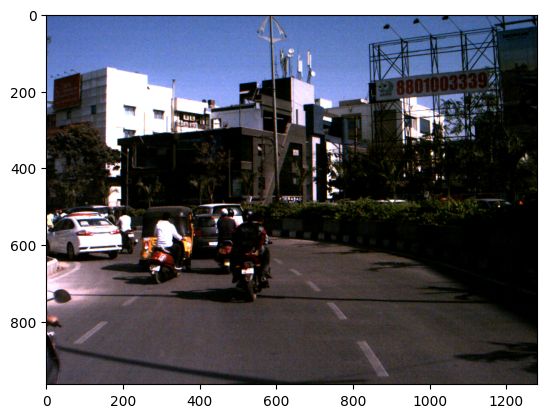

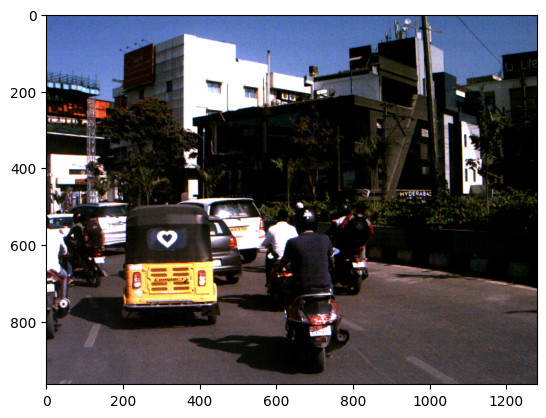

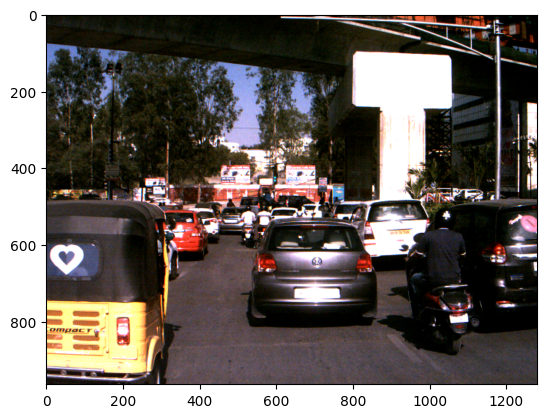

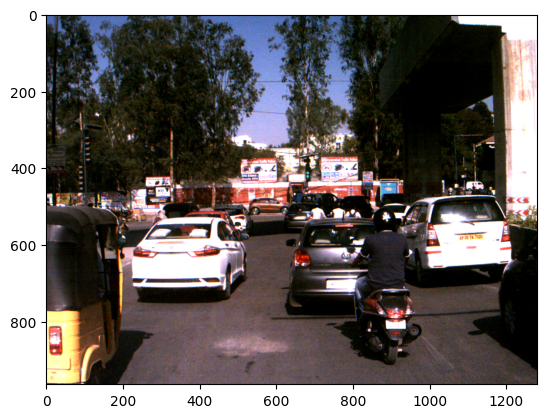

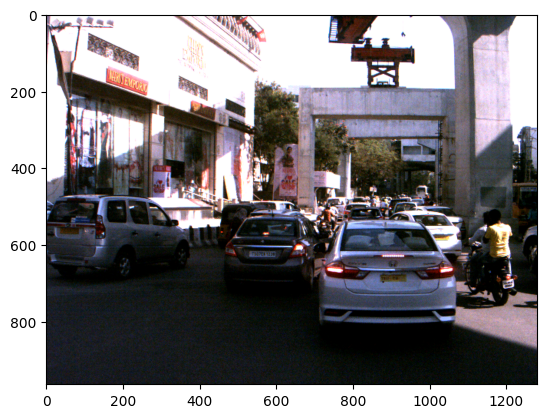

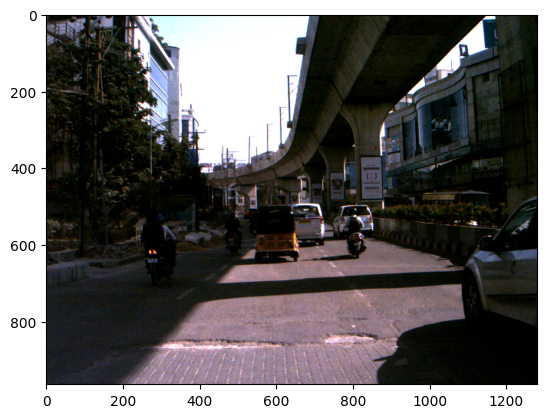

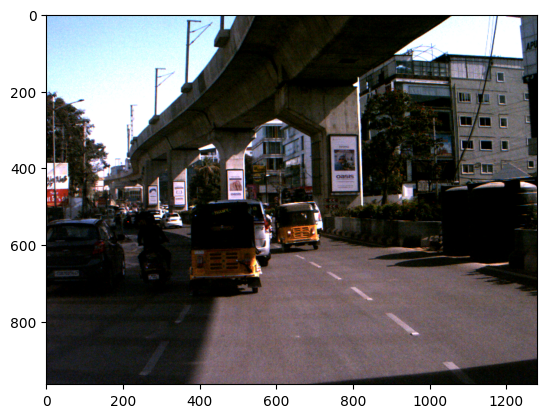

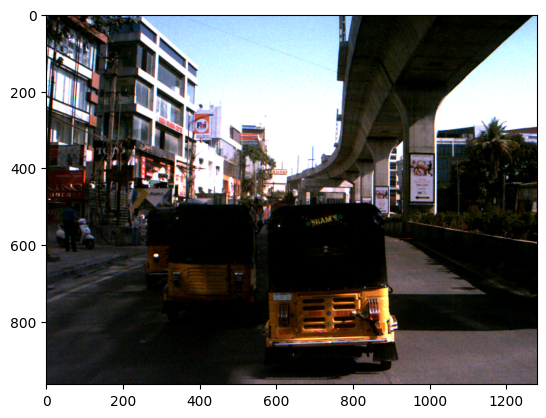

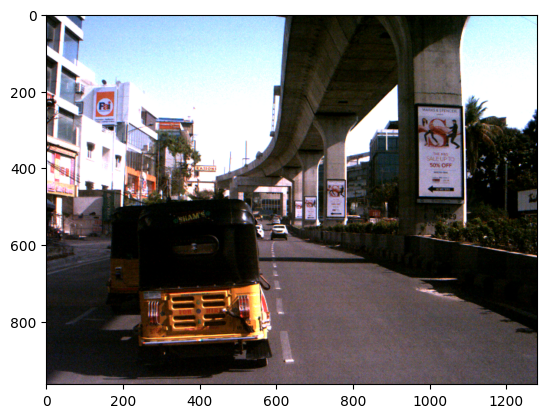

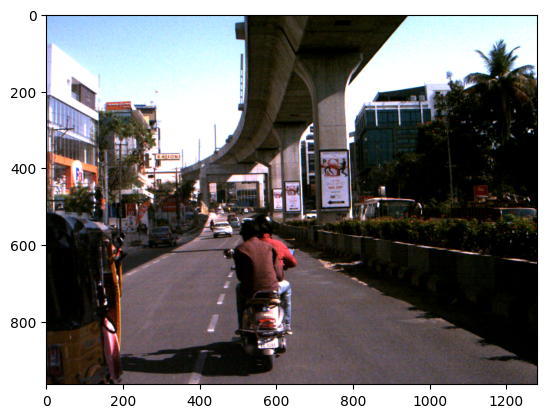

In [9]:
import matplotlib.pyplot as plt
images = os.listdir(train_path+"/"+city)[:10]
for image in images:
    path = train_path +"/"+city +"/"+image
    img = plt.imread(path)
    plt.imshow(img)
    plt.show()

In [15]:
mask_city = gt_path + "/" + city
print(os.listdir(mask_city)[:5])

['005506_gtFine_polygons.json', '005626_gtFine_polygons.json', '006741_gtFine_polygons.json', '006861_gtFine_polygons.json', '007325_gtFine_polygons.json']


In [19]:
import json

with open(mask_city + "/" + os.listdir(mask_city)[0]) as f:
    data = json.load(f)

print(data.keys())
print(data['objects'][0])  # see one annotated object

dict_keys(['imgHeight', 'imgWidth', 'objects'])
{'date': '13-Apr-2018 15:51:45', 'deleted': 0, 'draw': True, 'id': 37, 'label': 'vegetation', 'polygon': [[509.8076923076923, 491.2692307692308], [515.9871794871794, 491.2692307692308], [528.3461538461538, 495.3888888888889], [532.465811965812, 488.1794871794872], [538.6452991452992, 491.2692307692308], [545.8547008547008, 492.2991452991453], [549.974358974359, 486.11965811965814], [559.2435897435897, 486.11965811965814], [568.5128205128206, 484.05982905982904], [566.4529914529915, 493.3290598290598], [577.7820512820513, 492.2991452991453], [584.991452991453, 500.53846153846155], [583.9615384615385, 506.71794871794873], [582.9316239316239, 520.1068376068376], [574.6923076923077, 536.5854700854701], [561.3034188034188, 546.8846153846154], [535.5555555555555, 539.6752136752136], [512.8974358974359, 505.6880341880342], [509.8076923076923, 498.4786324786325]], 'user': 'cvit', 'verified': 0}


# LABEL SET (All labels)

# Color for Every Label

In [ ]:
label_colors = {
    "tunnel": [150,120,90],
    "non-drivable fallback": [156,60,200],
    "motorcycle": [0,0,230],
    "bridge": [150,100,100],
    "parking": [250,170,160],
    "sidewalk": [244,35,232],
    "animal": [199,151,187],
    "vegetation": [107,142,35],
    "road": [128,64,128],
    "person": [220,20,60],
    "billboard": [37,58,77],
    "fallback background": [225,130,180],
    "sky": [70,130,180],
    "curb": [196,209,152],
    "building": [70,70,70],
    "polegroup": [153,153,153],
    "autorickshaw": [99,250,80],
    "traffic light": [250,170,30],
    "rider": [255,0,0],
    "vehicle fallback": [82,92,214],
    "traffic sign": [220,220,0],
    "out of roi": [0,0,0],
    "bicycle": [119,11,32],
    "bus": [0,60,100],
    "obs-str-bar-fallback": [11,35,88],
    "wall": [102,102,156],
    "caravan": [0,0,90],
    "pole": [153,153,153],
    "fence": [190,153,153],
    "drivable fallback": [229,23,142],
    "guard rail": [180,165,180],
    "car": [0,0,142],
    "truck": [0,0,70],
    "license plate": [32,64,128],
    "rail track": [192,192,192],
    "rectification border": [89,202,34],
    "trailer": [50,150,250],
    "train": [35,105,70],
}

# Label ID for each Label

In [ ]:
label2id = {label: i+1 for i, label in enumerate(sorted(label_colors.keys()))}
print(label2id)

# JSON- MASK Conversion

In [ ]:
from PIL import Image, ImageDraw
import numpy as np

def polygons_to_mask(json_path, label2id):
    with open(json_path) as f:
        data = json.load(f)
    
    h, w = data['imgHeight'], data['imgWidth']
    mask = Image.new("L", (w, h), 0)  # "L" = single channel, 0 = background
    draw = ImageDraw.Draw(mask)
    
    for obj in data['objects']:
        label = obj['label']
        if label not in label2id:
            continue
        polygon = [tuple(p) for p in obj['polygon']]
        if len(polygon) >= 3:  # polygon needs at least 3 points
            draw.polygon(polygon, fill=label2id[label])
    
    return np.array(mask)

# Testing for 1 Image

In [11]:
json_file = mask_city + "/107080_gtFine_polygons.json"
mask = polygons_to_mask(json_file, label2id)
print(mask.shape, mask.dtype)
print(np.unique(mask))  #class IDs present hain

(1080, 1920) uint8
[ 2  4  6  8 16 18 21 22 26 27 28 29 34 36 38]


['044561_leftImg8bit.png', '641917_leftImg8bit.png', '698133_leftImg8bit.png', '102870_leftImg8bit.png', '709109_leftImg8bit.png']


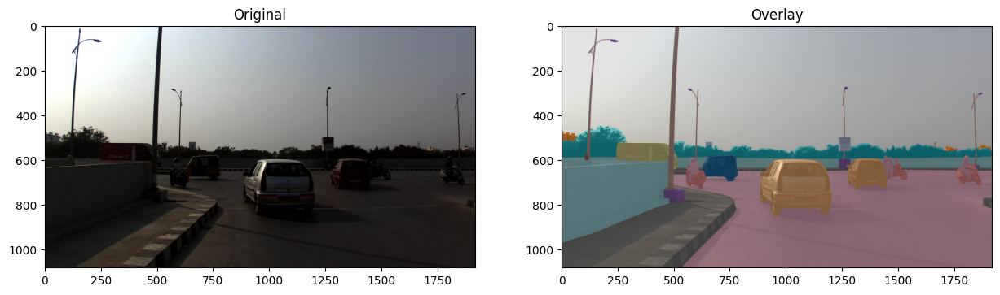

In [12]:
print(os.listdir(train_path + "/" + city)[:5])
import matplotlib.pyplot as plt
img_id = "107080"
json_file = mask_city + "/" + img_id + "_gtFine_polygons.json"
img_file = train_path + "/" + city + "/" + img_id + "_leftImg8bit.png"
mask = polygons_to_mask(json_file, label2id)
img = plt.imread(img_file)
plt.figure(figsize=(15,8))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original")
plt.subplot(1,2,2)
plt.imshow(img)
plt.imshow(mask, alpha=0.5, cmap='tab20')
plt.title("Overlay")
plt.show()

# Find all valid image-mask pairs

In [13]:
import os

print("Train path:", train_path)
print("GT path:", gt_path)

print("Image folders:", len(os.listdir(train_path)))
print("Annotation folders:", len(os.listdir(gt_path)))

Train path: /kaggle/input/datasets/vesusve/india-driving-dataset-idd/idd-segmentation/IDD_Segmentation/leftImg8bit/train
GT path: /kaggle/input/datasets/vesusve/india-driving-dataset-idd/idd-segmentation/IDD_Segmentation/gtFine/train
Image folders: 120
Annotation folders: 120


# Test

In [14]:
import os
from PIL import Image
from tqdm.auto import tqdm

MASK_DIR = "/kaggle/working/IDD_Masks"
os.makedirs(MASK_DIR, exist_ok=True)

test_pairs = []
cities = sorted(os.listdir(train_path))

for city in cities:
    img_dir = os.path.join(train_path, city)
    json_dir = os.path.join(gt_path, city)

    if not os.path.isdir(img_dir) or not os.path.isdir(json_dir):
        continue

    json_files = {
        f.replace("_gtFine_polygons.json", ""): os.path.join(json_dir, f)
        for f in os.listdir(json_dir)
        if f.endswith("_gtFine_polygons.json")
    }

    for f in sorted(os.listdir(img_dir)):
        if f.endswith("_leftImg8bit.png"):
            image_id = f.replace("_leftImg8bit.png", "")

            if image_id in json_files:
                mask_path = os.path.join(
                    MASK_DIR, f"{city}_{image_id}_mask.png"
                )

                test_pairs.append((
                    os.path.join(img_dir, f),
                    json_files[image_id],
                    mask_path
                ))

                if len(test_pairs) == 10:
                    break

    if len(test_pairs) == 10:
        break

print("Images selected for testing:", len(test_pairs))

generated = 0
errors = 0

for image_path, json_path, mask_path in tqdm(
    test_pairs, desc="Testing mask conversion", unit="image"
):
    try:
        mask = polygons_to_mask(json_path, label2id)
        Image.fromarray(mask.astype("uint8")).save(mask_path)
        generated += 1

    except Exception as e:
        errors += 1
        print(f"\nError: {json_path}\n{e}")

print("\nTest complete!")
print("Masks generated:", generated)
print("Errors:", errors)
print("Output folder:", MASK_DIR)

Images selected for testing: 10


Testing mask conversion:   0%|          | 0/10 [00:00<?, ?image/s]


Test complete!
Masks generated: 10
Errors: 0
Output folder: /kaggle/working/IDD_Masks


# Generation

In [17]:
import os
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

MASK_DIR = "/kaggle/working/IDD_Masks"
os.makedirs(MASK_DIR, exist_ok=True)

pairs = []
generated = 0
skipped = 0
errors = 0
all_pairs = []
cities = sorted(os.listdir(train_path))

print("Scanning training dataset...")

for city in tqdm(cities, desc="Scanning folders"):
    img_dir = os.path.join(train_path, city)
    json_dir = os.path.join(gt_path, city)

    if not os.path.isdir(img_dir) or not os.path.isdir(json_dir):
        continue

    json_files = {
        f.replace("_gtFine_polygons.json", ""):
        os.path.join(json_dir, f)
        for f in os.listdir(json_dir)
        if f.endswith("_gtFine_polygons.json")
    }

    for f in os.listdir(img_dir):
        if not f.endswith("_leftImg8bit.png"):
            continue

        image_id = f.replace("_leftImg8bit.png", "")

        if image_id in json_files:
            mask_path = os.path.join(
                MASK_DIR,
                f"{city}_{image_id}_mask.png"
            )

            all_pairs.append((
                os.path.join(img_dir, f),
                json_files[image_id],
                mask_path
            ))

print(f"\nTotal valid image-JSON pairs: {len(all_pairs)}")

# Step 2: Generate masks with live progress
with tqdm(
    total=len(all_pairs),
    desc="Generating masks",
    unit="mask"
) as pbar:

    for image_path, json_path, mask_path in all_pairs:
        try:
            if os.path.exists(mask_path):
                skipped += 1
            else:
                mask = polygons_to_mask(json_path, label2id)
                Image.fromarray(mask.astype("uint8")).save(mask_path)
                generated += 1

            pairs.append((image_path, mask_path))

        except Exception as e:
            errors += 1
            tqdm.write(
                f"Error in {os.path.basename(json_path)}: {e}"
            )

        pbar.update(1)
        pbar.set_postfix(
            generated=generated,
            skipped=skipped,
            errors=errors
        )

# Step 3: Create dataframe for later preprocessing
df = pd.DataFrame(
    pairs,
    columns=["image_path", "mask_path"]
)

print("Total valid pairs:", len(all_pairs))
print("New masks generated:", generated)
print("Existing masks skipped:", skipped)
print("Errors:", errors)
print("Valid image-mask pairs:", len(df))
print("Output directory:", MASK_DIR)

Scanning training dataset...


Scanning folders:   0%|          | 0/120 [00:00<?, ?it/s]


Total valid image-JSON pairs: 6993


Generating masks:   0%|          | 0/6993 [00:00<?, ?mask/s]

Total valid pairs: 6993
New masks generated: 6983
Existing masks skipped: 10
Errors: 0
Valid image-mask pairs: 6993
Output directory: /kaggle/working/IDD_Masks


# Verifying

In [18]:
import os
import pandas as pd

MASK_DIR = "/kaggle/working/IDD_Masks"

pairs = []

for city in sorted(os.listdir(train_path)):
    img_dir = os.path.join(train_path, city)

    if not os.path.isdir(img_dir):
        continue

    for filename in os.listdir(img_dir):
        if not filename.endswith("_leftImg8bit.png"):
            continue

        image_id = filename.replace("_leftImg8bit.png", "")
        image_path = os.path.join(img_dir, filename)

        mask_path = os.path.join(
            MASK_DIR, f"{city}_{image_id}_mask.png"
        )

        if os.path.exists(mask_path):
            pairs.append((image_path, mask_path))

df = pd.DataFrame(
    pairs,
    columns=["image_path", "mask_path"]
)

print("Total valid image-mask pairs:", len(df))
print("Missing masks:", 6993 - len(df))
print("Duplicate image paths:", df["image_path"].duplicated().sum())
print("Duplicate mask paths:", df["mask_path"].duplicated().sum())

display(df.head())

Total valid image-mask pairs: 6993
Missing masks: 0
Duplicate image paths: 0
Duplicate mask paths: 0


,image_path,mask_path
0,/kaggle/input/datasets/vesusve/india-driving-d...,/kaggle/working/IDD_Masks/0_020764_mask.png
1,/kaggle/input/datasets/vesusve/india-driving-d...,/kaggle/working/IDD_Masks/0_024541_mask.png
2,/kaggle/input/datasets/vesusve/india-driving-d...,/kaggle/working/IDD_Masks/0_007325_mask.png
3,/kaggle/input/datasets/vesusve/india-driving-d...,/kaggle/working/IDD_Masks/0_022141_mask.png
4,/kaggle/input/datasets/vesusve/india-driving-d...,/kaggle/working/IDD_Masks/0_012449_mask.png


In [19]:
import os
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

VAL_IMG_ROOT = DATASET_PATH + "/leftImg8bit/val"
VAL_GT_ROOT = DATASET_PATH + "/gtFine/val"
VAL_MASK_DIR = "/kaggle/working/IDD_Masks_val"
os.makedirs(VAL_MASK_DIR, exist_ok=True)

val_items = []
for city in sorted(os.listdir(VAL_IMG_ROOT)):
    img_dir = os.path.join(VAL_IMG_ROOT, city)
    json_dir = os.path.join(VAL_GT_ROOT, city)
    if not os.path.isdir(img_dir) or not os.path.isdir(json_dir):
        continue
    for f in os.listdir(img_dir):
        if not f.endswith("_leftImg8bit.png"):
            continue
        image_id = f.replace("_leftImg8bit.png", "")
        json_path = os.path.join(json_dir, image_id + "_gtFine_polygons.json")
        if os.path.exists(json_path):
            mask_path = os.path.join(VAL_MASK_DIR, f"{city}_{image_id}_mask.png")
            val_items.append((os.path.join(img_dir, f), json_path, mask_path))

print("Val image-JSON pairs:", len(val_items))

generated = 0
skipped = 0
errors = 0
for image_path, json_path, mask_path in tqdm(val_items, desc="Generating val masks", unit="mask"):
    if os.path.exists(mask_path):
        skipped += 1
        continue
    try:
        mask = polygons_to_mask(json_path, label2id)
        Image.fromarray(mask.astype("uint8")).save(mask_path)
        generated += 1
    except Exception as e:
        errors += 1
        print("Error:", json_path, e)

val_df = pd.DataFrame(
    [(i, m) for i, j, m in val_items if os.path.exists(m)],
    columns=["image_path", "mask_path"],
)

print("Generated:", generated)
print("Skipped:", skipped)
print("Errors:", errors)
print("Valid val image-mask pairs:", len(val_df))
print("Duplicate image paths:", val_df["image_path"].duplicated().sum())
display(val_df.head())

Val image-JSON pairs: 981


Generating val masks:   0%|          | 0/981 [00:00<?, ?mask/s]

Generated: 981
Skipped: 0
Errors: 0
Valid val image-mask pairs: 981
Duplicate image paths: 0


,image_path,mask_path
0,/kaggle/input/datasets/vesusve/india-driving-d...,/kaggle/working/IDD_Masks_val/119_500688_mask.png
1,/kaggle/input/datasets/vesusve/india-driving-d...,/kaggle/working/IDD_Masks_val/119_638495_mask.png
2,/kaggle/input/datasets/vesusve/india-driving-d...,/kaggle/working/IDD_Masks_val/119_893319_mask.png
3,/kaggle/input/datasets/vesusve/india-driving-d...,/kaggle/working/IDD_Masks_val/119_372819_mask.png
4,/kaggle/input/datasets/vesusve/india-driving-d...,/kaggle/working/IDD_Masks_val/119_222715_mask.png


In [20]:
import numpy as np
from PIL import Image

IGNORE = 255
ignore_ids = {0, label2id["out of roi"], label2id["rectification border"]}
keep_ids = [i for i in range(1, 39) if i not in ignore_ids]

lut = np.full(256, IGNORE, dtype=np.uint8)
for new_id, old_id in enumerate(keep_ids):
    lut[old_id] = new_id

NUM_CLASSES = len(keep_ids)
id2label = {v: k for k, v in label2id.items()}
class_names = [id2label[i] for i in keep_ids]

print("NUM_CLASSES:", NUM_CLASSES)
print("Ignored original IDs:", sorted(ignore_ids))

for name, path in [("train", df["mask_path"].iloc[0]), ("val", val_df["mask_path"].iloc[0])]:
    raw = np.array(Image.open(path))
    remapped = lut[raw]
    print(f"\n{name}: {path}")
    print("Original IDs:", np.unique(raw))
    print("Remapped IDs:", np.unique(remapped))
    print("Ignored pixels: %.2f%%" % (100 * (remapped == IGNORE).mean()))

for i, n in enumerate(class_names):
    print(i, n)

NUM_CLASSES: 36
Ignored original IDs: [0, 19, 25]

train: /kaggle/working/IDD_Masks/0_020764_mask.png
Original IDs: [ 0  2  4  5  6  8 10 11 16 17 18 21 22 26 27 29 36 37 38]
Remapped IDs: [  1   3   4   5   7   9  10  15  16  17  19  20  23  24  26  33  34  35
 255]
Ignored pixels: 0.10%

val: /kaggle/working/IDD_Masks_val/119_500688_mask.png
Original IDs: [ 0  4  6  7  8 11 18 22 27 29 31 34 36 37 38]
Remapped IDs: [  3   5   6   7  10  17  20  24  26  28  31  33  34  35 255]
Ignored pixels: 0.00%
0 animal
1 autorickshaw
2 bicycle
3 billboard
4 bridge
5 building
6 bus
7 car
8 caravan
9 curb
10 drivable fallback
11 fallback background
12 fence
13 guard rail
14 license plate
15 motorcycle
16 non-drivable fallback
17 obs-str-bar-fallback
18 parking
19 person
20 pole
21 polegroup
22 rail track
23 rider
24 road
25 sidewalk
26 sky
27 traffic light
28 traffic sign
29 trailer
30 train
31 truck
32 tunnel
33 vegetation
34 vehicle fallback
35 wall


# DATA PIPELINE

I0000 00:00:1791780290.308807      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791780290.312398      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Image batch: (16, 256, 512, 3) <dtype: 'float32'> range: -1.00 to 1.00
Mask batch: (16, 256, 512, 1) <dtype: 'int32'>
Mask values: [  1   2   3   4   5   6   7   9  10  12  13  15  16  17  19  20  21  23
  24  25  26  27  28  31  32  33  34  35 255]
Train batches: 437
Val batches: 62


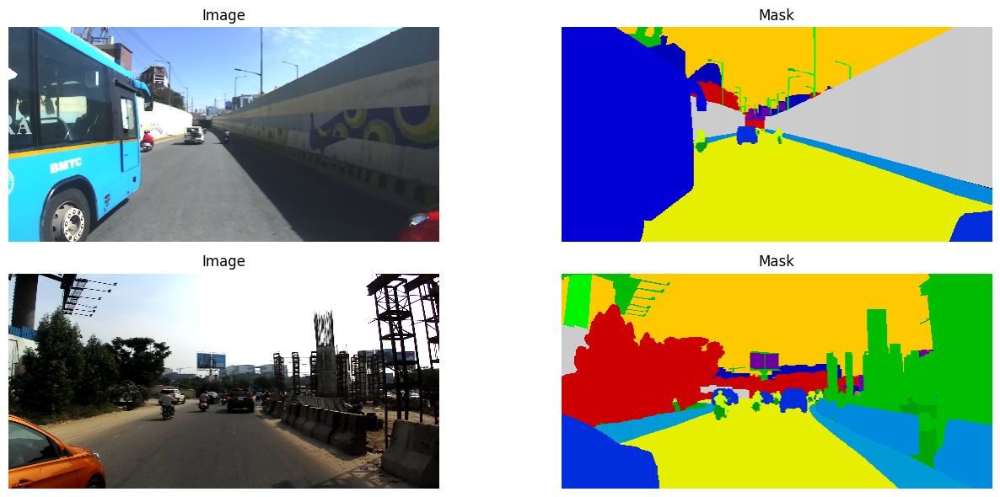

In [21]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

IMG_H = 256
IMG_W = 512
BATCH = 16
AUTOTUNE = tf.data.AUTOTUNE
LUT = tf.constant(lut.astype(np.int32), dtype=tf.int32)

def load_pair(img_path, mask_path):
    img = tf.io.decode_png(tf.io.read_file(img_path), channels=3)
    img = tf.image.resize(tf.cast(img, tf.float32), (IMG_H, IMG_W), method="bilinear")
    m = tf.io.decode_png(tf.io.read_file(mask_path), channels=1)
    m = tf.image.resize(tf.cast(m, tf.float32), (IMG_H, IMG_W), method="nearest")
    m = tf.cast(m, tf.int32)
    m = tf.gather(LUT, m[..., 0])
    m = tf.expand_dims(m, -1)
    return img, m

def augment(img, m):
    flip = tf.random.uniform(()) > 0.5
    img = tf.cond(flip, lambda: tf.image.flip_left_right(img), lambda: img)
    m = tf.cond(flip, lambda: tf.image.flip_left_right(m), lambda: m)
    img = tf.image.random_brightness(img, 25.0)
    img = tf.image.random_contrast(img, 0.8, 1.2)
    img = tf.clip_by_value(img, 0.0, 255.0)
    return img, m

def scale(img, m):
    return img / 127.5 - 1.0, m

def make_ds(frame, training):
    ds = tf.data.Dataset.from_tensor_slices(
        (frame["image_path"].values, frame["mask_path"].values)
    )
    if training:
        ds = ds.shuffle(1024, reshuffle_each_iteration=True)
    ds = ds.map(load_pair, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    ds = ds.map(scale, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH, drop_remainder=training)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(df, True)
val_ds = make_ds(val_df, False)

x, y = next(iter(train_ds))
print("Image batch:", x.shape, x.dtype, "range: %.2f to %.2f" % (x.numpy().min(), x.numpy().max()))
print("Mask batch:", y.shape, y.dtype)
print("Mask values:", np.unique(y.numpy()))
print("Train batches:", len(df) // BATCH)
print("Val batches:", -(-len(val_df) // BATCH))

fig, ax = plt.subplots(2, 2, figsize=(14, 6))
for i in range(2):
    ax[i, 0].imshow((x[i].numpy() + 1) / 2)
    ax[i, 0].set_title("Image")
    shown = np.where(y[i, ..., 0].numpy() == 255, -1, y[i, ..., 0].numpy())
    ax[i, 1].imshow(shown, cmap="nipy_spectral", vmin=-1, vmax=NUM_CLASSES - 1)
    ax[i, 1].set_title("Mask")
    ax[i, 0].axis("off")
    ax[i, 1].axis("off")
plt.tight_layout()
plt.show()

In [22]:
import numpy as np
import tensorflow as tf
import keras_hub

strategy = tf.distribute.MirroredStrategy()
print("Replicas:", strategy.num_replicas_in_sync)

with strategy.scope():
    model = keras_hub.models.DeepLabV3ImageSegmenter.from_preset(
        "deeplab_v3_plus_resnet50_pascalvoc",
        num_classes=NUM_CLASSES,
    )

in_shape = model.inputs[0].shape
print("Model input shape:", in_shape)
print("Model output shape:", model.output_shape)
print("Total params: {:,}".format(model.count_params()))

if in_shape[1] is not None and in_shape[2] is not None:
    IMG_H, IMG_W = int(in_shape[1]), int(in_shape[2])
    print("Fixed input size, using", IMG_H, "x", IMG_W)

MEAN = tf.constant([0.485, 0.456, 0.406], dtype=tf.float32) * 255.0
STD = tf.constant([0.229, 0.224, 0.225], dtype=tf.float32) * 255.0

def scale(img, m):
    return (img - MEAN) / STD, m

PER_REPLICA_BATCH = 4 if IMG_H * IMG_W > 256 * 512 else 8
BATCH = PER_REPLICA_BATCH * strategy.num_replicas_in_sync
print("Global batch size:", BATCH)

train_ds = make_ds(df, True)
val_ds = make_ds(val_df, False)

x, y = next(iter(train_ds))
print("Image batch:", x.shape, "range: %.2f to %.2f" % (x.numpy().min(), x.numpy().max()))
print("Mask batch:", y.shape, y.dtype)

out = model(x[:2], training=False)
print("Test forward pass:", out.shape, out.dtype)
print("Output finite:", bool(tf.reduce_all(tf.math.is_finite(out))))
print("Sum over classes at one pixel:", float(tf.reduce_sum(out[0, 0, 0])))
print("GPUs:", tf.config.list_physical_devices("GPU"))

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Replicas: 2
Model input shape: (None, None, None, 3)
Model output shape: (None, None, None, 36)
Total params: 39,199,872
Global batch size: 16
Image batch: (16, 256, 512, 3) range: -2.12 to 2.64
Mask batch: (16, 256, 512, 1) <dtype: 'int32'>
Test forward pass: (2, 256, 512, 36) <dtype: 'float32'>
Output finite: True
Sum over classes at one pixel: 1.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [25]:
import keras
from keras import layers
import tensorflow as tf
import time

IMG_H, IMG_W = 256, 512
BATCH = 8 * strategy.num_replicas_in_sync

def scale(img, m):
    return tf.keras.applications.resnet50.preprocess_input(img), m

train_ds = make_ds(df, True)
val_ds = make_ds(val_df, False)

def conv_block(x, filters):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    return x

def build_resnet_unet(num_classes, img_h, img_w):
    encoder = keras.applications.ResNet50(
        include_top=False,
        weights="imagenet",
        input_shape=(img_h, img_w, 3),
    )
    s1 = encoder.get_layer("conv1_relu").output
    s2 = encoder.get_layer("conv2_block3_out").output
    s3 = encoder.get_layer("conv3_block4_out").output
    s4 = encoder.get_layer("conv4_block6_out").output
    x = encoder.get_layer("conv5_block3_out").output

    for skip, filters in zip([s4, s3, s2, s1], [512, 256, 128, 64]):
        x = layers.UpSampling2D(interpolation="bilinear")(x)
        x = layers.Concatenate()([x, skip])
        x = conv_block(x, filters)

    x = layers.UpSampling2D(interpolation="bilinear")(x)
    x = conv_block(x, 32)
    outputs = layers.Conv2D(num_classes, 1, activation="softmax", dtype="float32")(x)
    return keras.Model(encoder.input, outputs, name="resnet50_unet")

with strategy.scope():
    model = build_resnet_unet(NUM_CLASSES, IMG_H, IMG_W)
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=2e-4, weight_decay=1e-4),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False, ignore_class=IGNORE),
        metrics=[
            keras.metrics.MeanIoU(
                num_classes=NUM_CLASSES,
                ignore_class=IGNORE,
                sparse_y_true=True,
                sparse_y_pred=False,
                name="mIoU",
            )
        ],
        jit_compile=False,
    )

print("Input:", model.input_shape)
print("Output:", model.output_shape)
print("Params: {:,}".format(model.count_params()))

x, y = next(iter(train_ds))
print("Image batch:", x.shape, "range: %.1f to %.1f" % (x.numpy().min(), x.numpy().max()))

start = time.time()
test_history = model.fit(train_ds.take(10), epochs=1, verbose=1)
print("Test fit finished in %.1f s" % (time.time() - start))
print("Loss:", test_history.history["loss"][0], "| mIoU:", test_history.history["mIoU"][0])

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Input: (None, 256, 512, 3)
Output: (None, 256, 512, 36)
Params: 43,973,412
Image batch: (16, 256, 512, 3) range: -123.7 to 151.1
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Collective all_reduce tensors: 244 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
10/10 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step - loss: 3.2861 - mIoU: 0.0327  
Test fit finished in 77.7 s
Loss: 3.2860522270202637 | mIoU: 0.03268098086118698


In [26]:
EPOCHS = 5
steps_per_epoch = len(df) // BATCH

with strategy.scope():
    lr_schedule = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=2e-4,
        decay_steps=EPOCHS * steps_per_epoch,
        alpha=0.05,
    )
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=lr_schedule, weight_decay=1e-4),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False, ignore_class=IGNORE),
        metrics=[
            keras.metrics.MeanIoU(
                num_classes=NUM_CLASSES,
                ignore_class=IGNORE,
                sparse_y_true=True,
                sparse_y_pred=False,
                name="mIoU",
            )
        ],
        jit_compile=False,
    )

callbacks = [
    keras.callbacks.ModelCheckpoint(
        "/kaggle/working/idd_resnet_unet_best.weights.h5",
        monitor="val_mIoU",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1,
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)

Epoch 1/5
INFO:tensorflow:Collective all_reduce tensors: 244 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
437/437 ━━━━━━━━━━━━━━━━━━━━ 0s 957ms/step - loss: 1.9595 - mIoU: 0.1585
Epoch 1: val_mIoU improved from None to 0.29574, saving model to /kaggle/working/idd_resnet_unet_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/idd_resnet_unet_best.weights.h5
437/437 ━━━━━━━━━━━━━━━━━━━━ 509s 1s/step - loss: 1.5589 - mIoU: 0.2121 - val_loss: 1.0625 - val_mIoU: 0.2957
Epoch 2/5
437/437 ━━━━━━━━━━━━━━━━━━━━ 0s 967ms/step - loss: 0.8963 - mIoU: 0.3176
Epoch 2: val_mIoU improved from 0.29574 to 0.34778, saving model to /kaggle/working/idd_resnet_unet_best.weights.h5

Epoch 2: finished saving model to /kaggle/working/idd_resnet_unet_best.weights.h5
437/437 ━━━━━━━━━━━━━━━━━━━━ 451s 1s/step - loss: 0.7949 - mIoU: 0.3158 - val_loss: 0.6653 - val_mIoU: 0.3478
Epoch 3/5
437/437 ━━━━━━━━━━━━━━━━━━━━ 0s 969ms/step - lo

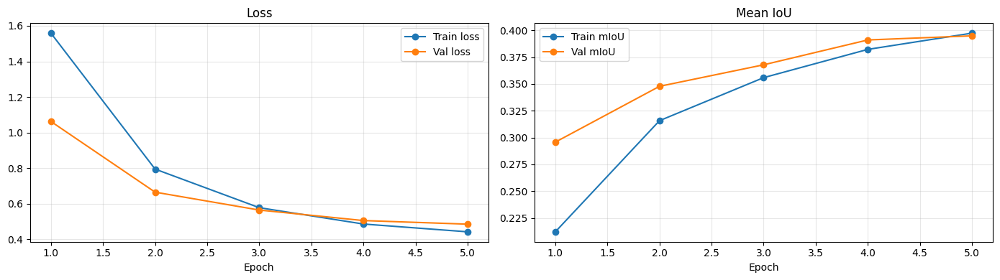

Best epoch: 5
Best val mIoU: 0.3949
Val loss at best epoch: 0.4855


In [27]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].plot(epochs_range, history.history["loss"], marker="o", label="Train loss")
ax[0].plot(epochs_range, history.history["val_loss"], marker="o", label="Val loss")
ax[0].set_title("Loss")
ax[0].set_xlabel("Epoch")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(epochs_range, history.history["mIoU"], marker="o", label="Train mIoU")
ax[1].plot(epochs_range, history.history["val_mIoU"], marker="o", label="Val mIoU")
ax[1].set_title("Mean IoU")
ax[1].set_xlabel("Epoch")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

best = int(np.argmax(history.history["val_mIoU"]))
print("Best epoch:", best + 1)
print("Best val mIoU: %.4f" % history.history["val_mIoU"][best])
print("Val loss at best epoch: %.4f" % history.history["val_loss"][best])

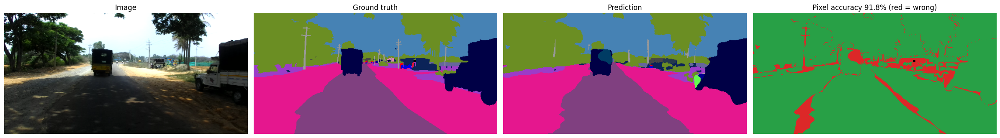

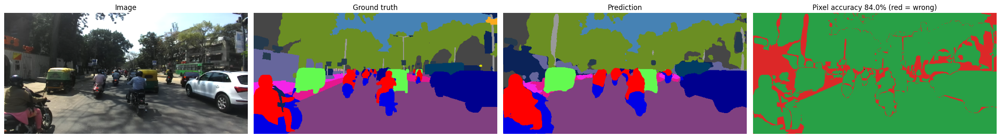

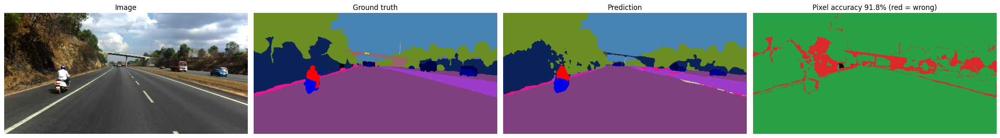

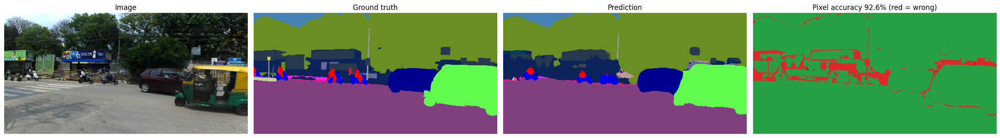

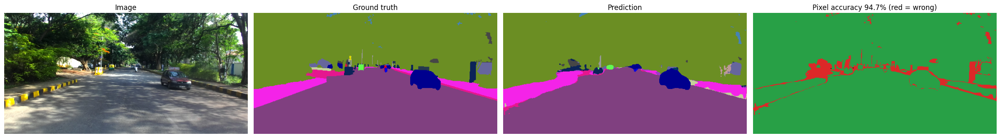

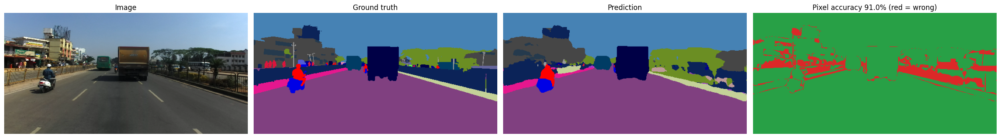

In [28]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

WEIGHTS = "/kaggle/working/idd_resnet_unet_best.weights.h5"
if os.path.exists(WEIGHTS):
    model.load_weights(WEIGHTS)

palette = np.zeros((NUM_CLASSES + 1, 3), dtype=np.uint8)
for i, name in enumerate(class_names):
    palette[i] = label_colors[name]

def colorize(m):
    return palette[np.where(m == IGNORE, NUM_CLASSES, m)]

rng = np.random.RandomState(7)
for idx in rng.choice(len(val_df), 6, replace=False):
    row = val_df.iloc[idx]
    raw_img, true_mask = load_pair(row["image_path"], row["mask_path"])
    inp = tf.keras.applications.resnet50.preprocess_input(raw_img[None])
    pred_mask = tf.argmax(model(inp, training=False), axis=-1)[0].numpy()
    true_np = true_mask[..., 0].numpy()

    valid = true_np != IGNORE
    wrong = np.zeros(true_np.shape + (3,), dtype=np.uint8)
    wrong[valid & (pred_mask == true_np)] = [40, 160, 70]
    wrong[valid & (pred_mask != true_np)] = [220, 40, 40]
    acc = (pred_mask[valid] == true_np[valid]).mean()

    fig, ax = plt.subplots(1, 4, figsize=(24, 4))
    ax[0].imshow(raw_img.numpy().astype(np.uint8))
    ax[0].set_title("Image")
    ax[1].imshow(colorize(true_np))
    ax[1].set_title("Ground truth")
    ax[2].imshow(colorize(pred_mask))
    ax[2].set_title("Prediction")
    ax[3].imshow(wrong)
    ax[3].set_title("Pixel accuracy %.1f%% (red = wrong)" % (100 * acc))
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
import os
import keras

EPOCHS = 15
steps_per_epoch = len(df) // BATCH

model.load_weights("/kaggle/working/idd_resnet_unet_best.weights.h5")

with strategy.scope():
    lr_schedule = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=1e-4,
        decay_steps=EPOCHS * steps_per_epoch,
        alpha=0.02,
    )
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=lr_schedule, weight_decay=1e-4),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False, ignore_class=IGNORE),
        metrics=[
            keras.metrics.MeanIoU(
                num_classes=NUM_CLASSES,
                ignore_class=IGNORE,
                sparse_y_true=True,
                sparse_y_pred=False,
                name="mIoU",
            )
        ],
        jit_compile=False,
    )

callbacks = [
    keras.callbacks.ModelCheckpoint(
        "/kaggle/working/idd_resnet_unet_v2.weights.h5",
        monitor="val_mIoU",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1,
    ),
]

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)

Epoch 1/15
INFO:tensorflow:Collective all_reduce tensors: 244 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
437/437 ━━━━━━━━━━━━━━━━━━━━ 0s 974ms/step - loss: 0.4467 - mIoU: 0.4158
Epoch 1: val_mIoU improved from None to 0.38803, saving model to /kaggle/working/idd_resnet_unet_v2.weights.h5

Epoch 1: finished saving model to /kaggle/working/idd_resnet_unet_v2.weights.h5
437/437 ━━━━━━━━━━━━━━━━━━━━ 511s 1s/step - loss: 0.4327 - mIoU: 0.3897 - val_loss: 0.4715 - val_mIoU: 0.3880
Epoch 2/15
437/437 ━━━━━━━━━━━━━━━━━━━━ 0s 976ms/step - loss: 0.3983 - mIoU: 0.4211
Epoch 2: val_mIoU did not improve from 0.38803
437/437 ━━━━━━━━━━━━━━━━━━━━ 453s 1s/step - loss: 0.3892 - mIoU: 0.3989 - val_loss: 0.4618 - val_mIoU: 0.3879
Epoch 3/15
437/437 ━━━━━━━━━━━━━━━━━━━━ 0s 973ms/step - loss: 0.3693 - mIoU: 0.4364
Epoch 3: val_mIoU improved from 0.38803 to 0.40487, saving model to /kaggle/working/idd_resnet_unet_v2.weights.h5

Epoch 3: fin

Mean IoU: 0.4540
Pixel accuracy: 0.8824

Per-class IoU:
sky                      0.9616
road                     0.9282
car                      0.8504
vegetation               0.8456
bus                      0.8144
truck                    0.7826
autorickshaw             0.7781
bridge                   0.6704
motorcycle               0.6436
rider                    0.6376
curb                     0.6136
building                 0.6080
traffic sign             0.6034
sidewalk                 0.5855
drivable fallback        0.5840
wall                     0.5722
person                   0.5056
billboard                0.5022
non-drivable fallback    0.4957
pole                     0.3792
guard rail               0.3509
obs-str-bar-fallback     0.3424
vehicle fallback         0.2501
fence                    0.1907
bicycle                  0.0326
parking                  0.0000
polegroup                0.0000
fallback background      0.0000
caravan                  0.0000
animal          

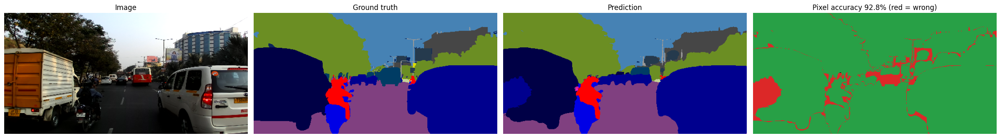

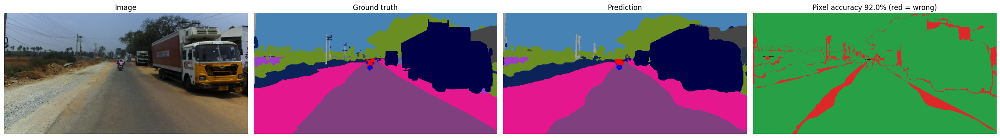

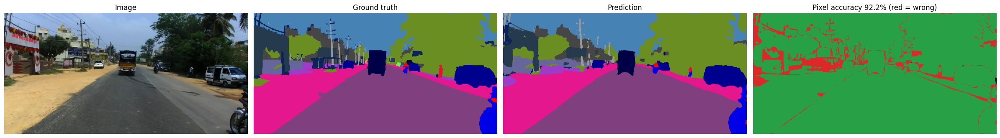

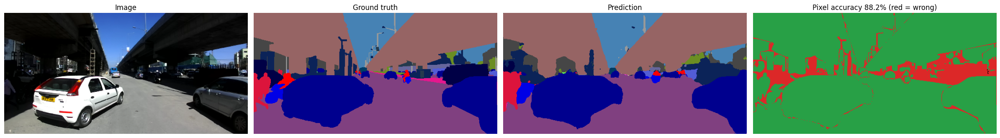

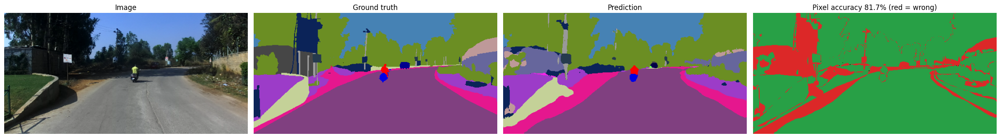

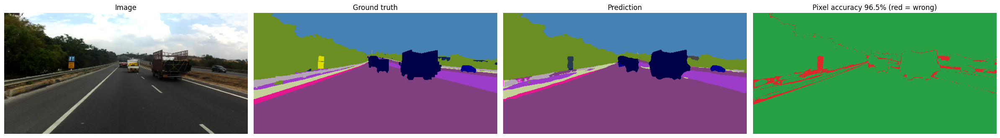

In [33]:
import gc
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

gc.collect()

model.load_weights("/kaggle/working/idd_resnet_unet_v2.weights.h5")

val_small = val_ds.unbatch().batch(4).prefetch(tf.data.AUTOTUNE)

cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
for xb, yb in val_small:
    pred = tf.argmax(model(xb, training=False), axis=-1).numpy().ravel()
    true = yb[..., 0].numpy().ravel()
    keep = true != IGNORE
    cm += tf.math.confusion_matrix(true[keep], pred[keep], num_classes=NUM_CLASSES).numpy()

tp = np.diag(cm).astype(np.float64)
denom = cm.sum(0) + cm.sum(1) - tp
present = cm.sum(1) > 0
iou = np.where(denom > 0, tp / np.maximum(denom, 1), 0.0)

print("Mean IoU: %.4f" % iou[present].mean())
print("Pixel accuracy: %.4f" % (tp.sum() / cm.sum()))
print("\nPer-class IoU:")
for i in np.argsort(-iou):
    if present[i]:
        print("%-24s %.4f" % (class_names[i], iou[i]))

palette = np.zeros((NUM_CLASSES + 1, 3), dtype=np.uint8)
for i, name in enumerate(class_names):
    palette[i] = label_colors[name]

def colorize(m):
    return palette[np.where(m == IGNORE, NUM_CLASSES, m)]

rng = np.random.RandomState(11)
for idx in rng.choice(len(val_df), 6, replace=False):
    row = val_df.iloc[idx]
    raw_img, true_mask = load_pair(row["image_path"], row["mask_path"])
    inp = tf.keras.applications.resnet50.preprocess_input(raw_img[None])
    pred_mask = tf.argmax(model(inp, training=False), axis=-1)[0].numpy()
    true_np = true_mask[..., 0].numpy()

    valid = true_np != IGNORE
    wrong = np.zeros(true_np.shape + (3,), dtype=np.uint8)
    wrong[valid & (pred_mask == true_np)] = [40, 160, 70]
    wrong[valid & (pred_mask != true_np)] = [220, 40, 40]
    acc = (pred_mask[valid] == true_np[valid]).mean()

    fig, ax = plt.subplots(1, 4, figsize=(24, 4))
    ax[0].imshow(raw_img.numpy().astype(np.uint8))
    ax[0].set_title("Image")
    ax[1].imshow(colorize(true_np))
    ax[1].set_title("Ground truth")
    ax[2].imshow(colorize(pred_mask))
    ax[2].set_title("Prediction")
    ax[3].imshow(wrong)
    ax[3].set_title("Pixel accuracy %.1f%% (red = wrong)" % (100 * acc))
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()

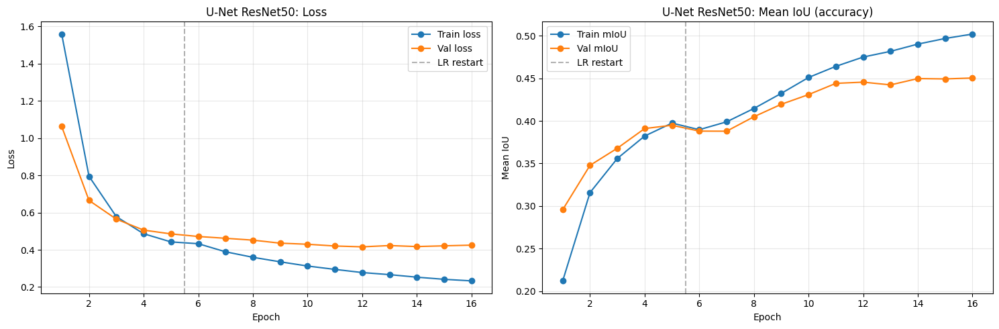

Final train loss: 0.2330 | val loss: 0.4250
Final train mIoU: 0.5020 | val mIoU: 0.4504
Best val mIoU: 0.4504 at epoch 16


In [34]:
import numpy as np
import matplotlib.pyplot as plt

loss = [1.5589, 0.7949, 0.5781, 0.4863, 0.4424,
        0.4327, 0.3892, 0.3597, 0.3353, 0.3128, 0.2948, 0.2778, 0.2666, 0.2529, 0.2415, 0.2330]
val_loss = [1.0625, 0.6653, 0.5647, 0.5057, 0.4855,
            0.4715, 0.4618, 0.4519, 0.4356, 0.4298, 0.4204, 0.4159, 0.4228, 0.4174, 0.4213, 0.4250]
miou = [0.2121, 0.3158, 0.3559, 0.3822, 0.3974,
        0.3897, 0.3989, 0.4146, 0.4323, 0.4510, 0.4641, 0.4750, 0.4817, 0.4902, 0.4968, 0.5020]
val_miou = [0.2957, 0.3478, 0.3679, 0.3910, 0.3949,
            0.3880, 0.3879, 0.4049, 0.4195, 0.4309, 0.4441, 0.4455, 0.4423, 0.4497, 0.4493, 0.4504]

epochs = np.arange(1, len(loss) + 1)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].plot(epochs, loss, marker="o", label="Train loss")
ax[0].plot(epochs, val_loss, marker="o", label="Val loss")
ax[0].axvline(5.5, color="gray", linestyle="--", alpha=0.6, label="LR restart")
ax[0].set_title("U-Net ResNet50: Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(epochs, miou, marker="o", label="Train mIoU")
ax[1].plot(epochs, val_miou, marker="o", label="Val mIoU")
ax[1].axvline(5.5, color="gray", linestyle="--", alpha=0.6, label="LR restart")
ax[1].set_title("U-Net ResNet50: Mean IoU (accuracy)")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Mean IoU")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/unet_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print("Final train loss: %.4f | val loss: %.4f" % (loss[-1], val_loss[-1]))
print("Final train mIoU: %.4f | val mIoU: %.4f" % (miou[-1], val_miou[-1]))
print("Best val mIoU: %.4f at epoch %d" % (max(val_miou), int(np.argmax(val_miou)) + 1))